<a href="https://colab.research.google.com/github/evelcueva1120-stack/diplomado-m6-evelyn-cueva/blob/main/talleres_Evelyn_Alexandra_Cueva_Gallo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- m6:clase=3;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 3 — Inferencia bayesiana con PyMC, redes bayesianas y simulador de fraude
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · viernes 13-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas de demostración ya están completas.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas.
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta `talleres/clase3.ipynb` → mensaje `Clase 3`.

> Datos: app de pagos móviles **PagoYa** (ficticia, simulada con fines didácticos).

## 0. Preparación y registro (Checkpoint 0)

In [ ]:
import importlib, subprocess, sys                            # instala lo que falte (solo la primera vez, ~30 s)
for paquete in ['pymc', 'pgmpy']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
print('Paquetes listos')

Paquetes listos


In [ ]:
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):                          # funciones del curso (incluye el simulador de la app)
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm                                           # programación probabilística (MCMC)
logging.getLogger('pymc').setLevel(logging.ERROR)          # menos mensajes en pantalla
from sklearn.model_selection import train_test_split
plt.rcParams['figure.figsize'] = (10, 3.4)
sigmoide = lambda z: 1 / (1 + np.exp(-z))                    # de log-odds a probabilidad
print('Listo · curso', curso.VERSION, '· PyMC', pm.__version__)

Listo · curso m6-2026.11 · PyMC 5.28.5


### ✏️ Checkpoint 0 · ⏱ 2 min
Registre su nombre como **'Apellido Nombre'** e indique la **clase 3**.

In [ ]:
curso.registrar('Cueva Gallo Evelyn Alexandra', clase=3)          # ✏️ su apellido y nombre, y el número de esta clase

Estudiante registrado: Cueva Gallo Evelyn Alexandra
Clase 3
✅ Checkpoint 0 correcto · código K0-72F4


In [ ]:
df = curso.cargar_pagoya_limpio()                           # mismos datos y limpieza de las clases 1 y 2
df['ratio'] = df['monto'] / df['ingreso_mensual']            # monto relativo al ingreso del usuario
imb = df[df['provincia'] == 'Imbabura']
k, n = int(imb['fraude'].sum()), len(imb)                    # 3 fraudes en 130 transacciones
print(f'Imbabura: {k} fraudes en {n} transacciones')

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
Imbabura: 3 fraudes en 130 transacciones


---
## 3.1 Inferencia bayesiana computacional con PyMC
Ayer la posterior de la tasa de Imbabura tenía **fórmula cerrada** (Beta). En casi todos los modelos reales no la hay: se obtienen **muestras** de la posterior con **MCMC** (cadenas de Markov Monte Carlo). PyMC usa el algoritmo **NUTS**. Primero lo comprobamos con el caso conocido.

### ✏️ Checkpoint 1 · ⏱ 6 min
Escriba el modelo beta-binomial en PyMC: prior **Beta(2, 20)** y verosimilitud **Binomial(n, tasa)** con `observed=k`. Obtenga la **media posterior**.

In [ ]:
with pm.Model() as modelo_tasa:
    tasa = pm.Beta('tasa', alpha=2, beta=20)                    # ✏️ prior
    pm.Binomial('obs', n=n, p=tasa, observed=k)                 # ✏️ verosimilitud
    tr_tasa = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
media_mcmc = float(tr_tasa.posterior['tasa'].mean())
print(f'MCMC: {media_mcmc:.4f} · fórmula exacta (a+k)/(a+b+n): {(2 + k) / (22 + n):.4f}')
curso.checkpoint(1, media_mcmc)

MCMC: 0.0331 · fórmula exacta (a+k)/(a+b+n): 0.0329
✅ Checkpoint 1 correcto · código K1-C907


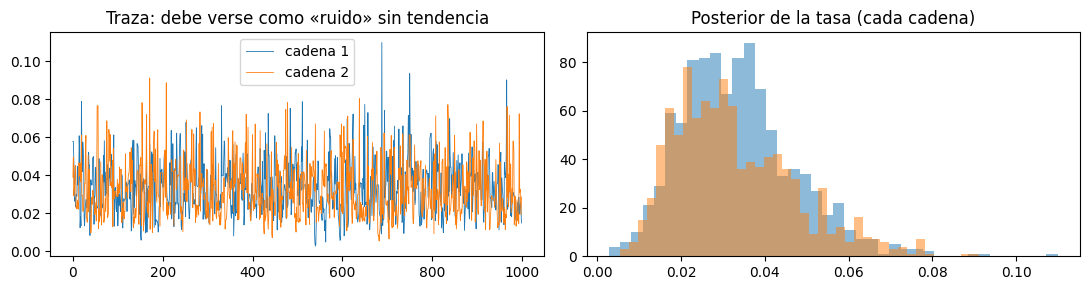

,media,desv,ic_3%,ic_97%,r_hat,ess
tasa,0.0331,0.0141,0.0124,0.0636,1.0001,840.8111


In [ ]:
x = tr_tasa.posterior['tasa'].values                         # matriz cadenas × muestras
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for c in range(x.shape[0]):
    ax[0].plot(x[c], lw=0.6, label=f'cadena {c + 1}'); ax[1].hist(x[c], bins=40, alpha=0.5)
ax[0].set_title('Traza: debe verse como «ruido» sin tendencia'); ax[0].legend()
ax[1].set_title('Posterior de la tasa (cada cadena)'); plt.tight_layout(); plt.show()
curso.diagnostico(tr_tasa, ['tasa'])

---
## 3.2 Redes bayesianas con pgmpy
Una **red bayesiana** es un grafo dirigido: cada nodo es una variable y cada flecha, una dependencia directa. Cada nodo tiene una **tabla de probabilidad condicional** (CPT) dada por sus padres. Ejemplo de **riesgo de impago** de un usuario de PagoYa con microcrédito:

`Desempleo → Mora ← IngresoBajo`, `Mora → Default`, `Desempleo → Default`

In [ ]:
try:
    from pgmpy.models import DiscreteBayesianNetwork as RedBayesiana   # pgmpy ≥ 1.0
except ImportError:
    from pgmpy.models import BayesianNetwork as RedBayesiana           # versiones anteriores
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

red = RedBayesiana([('Desempleo', 'Mora'), ('IngresoBajo', 'Mora'), ('Mora', 'Default'), ('Desempleo', 'Default')])
cpd_d = TabularCPD('Desempleo', 2, [[0.92], [0.08]])                  # P(Desempleo = 1) = 8 %
cpd_i = TabularCPD('IngresoBajo', 2, [[0.70], [0.30]])                # P(IngresoBajo = 1) = 30 %
cpd_m = TabularCPD('Mora', 2, [[0.95, 0.80, 0.70, 0.45],              # P(Mora | Desempleo, IngresoBajo)
                               [0.05, 0.20, 0.30, 0.55]], evidence=['Desempleo', 'IngresoBajo'], evidence_card=[2, 2])
cpd_f = TabularCPD('Default', 2, [[0.98, 0.85, 0.90, 0.60],           # P(Default | Mora, Desempleo)
                                  [0.02, 0.15, 0.10, 0.40]], evidence=['Mora', 'Desempleo'], evidence_card=[2, 2])
red.add_cpds(cpd_d, cpd_i, cpd_m, cpd_f)
print('Modelo válido:', red.check_model())
inferencia = VariableElimination(red)                                 # inferencia exacta
print('P(Default = 1) sin evidencia:', round(inferencia.query(['Default']).values[1], 4))

Modelo válido: True
P(Default = 1) sin evidencia: 0.0449


### ✏️ Checkpoint 2 · ⏱ 4 min
Calcule **P(Default = 1 | Mora = 1)**: la probabilidad de impago de un cliente que ya está en mora.

In [ ]:
p_default_mora = inferencia.query(['Default'], evidence={'Mora': 1}).values[1]   # ✏️
print(f'P(Default | Mora) = {p_default_mora:.4f}')
curso.checkpoint(2, p_default_mora)

P(Default | Mora) = 0.1767
✅ Checkpoint 2 correcto · código K2-CBDE


In [ ]:
casos = {'Mora': {'Mora': 1}, 'Mora + ingreso bajo': {'Mora': 1, 'IngresoBajo': 1}, 'Mora + desempleo': {'Mora': 1, 'Desempleo': 1}}
for nombre, ev in casos.items():                               # razonamiento PREDICTIVO (causas → efecto)
    print(f'P(Default | {nombre:<20}) = {inferencia.query(["Default"], evidence=ev).values[1]:.3f}')
print(f'P(Desempleo | Default) = {inferencia.query(["Desempleo"], evidence={"Default": 1}).values[1]:.3f}  ← razonamiento DIAGNÓSTICO')

P(Default | Mora                ) = 0.177
P(Default | Mora + ingreso bajo ) = 0.158
P(Default | Mora + desempleo    ) = 0.400
P(Desempleo | Default) = 0.434  ← razonamiento DIAGNÓSTICO


### 💬 Pregunta 1
Con mora, P(Default) = 0,177; si además sabemos que el ingreso es bajo, baja a 0,158. ¿Por qué más información «mala» reduce el riesgo?

**Respuesta:**

Es el efecto **explaining away** (explicación alternativa). La mora tiene dos causas posibles: desempleo o ingreso bajo. Si ya sé que el ingreso es bajo, esa causa «explica» la mora y el desempleo se vuelve menos probable: P(Desempleo | Mora) = 0,256 baja a P(Desempleo | Mora, IngresoBajo) = 0,193 (sección A). Como el desempleo tiene una flecha **directa** a Default (además de la que pasa por Mora), al bajar el desempleo baja el riesgo de impago. El ingreso bajo, en cambio, no afecta al Default salvo a través de la mora, que ya está observada.

---
## 3.3 Regresión logística bayesiana y modelo jerárquico
**Regresión logística bayesiana**: log-odds(fraude) = a + b · X, con **priors** sobre a y b. El resultado no es un coeficiente sino una **distribución** para cada uno.

In [ ]:
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3, stratify=df['fraude'], random_state=42)
media, desv = X_train.mean(), X_train.std()                  # estandarizar con datos de ENTRENAMIENTO
Z = ((X_train - media) / desv).values
with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                         # prior del intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))        # priors de los coeficientes (regularizan)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z, b), observed=y_train.values)
    tr_log = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
diag = curso.diagnostico(tr_log, ['a', 'b']); diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)           # efecto de +1 desviación estándar
diag

,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.4305,0.1473,-3.7059,-3.1690,1.0007,1112.1984,0.03
dispositivo_nuevo,1.0003,0.0747,0.8609,1.1388,0.9994,1365.4942,2.72
distancia_km,0.5420,0.0784,0.3948,0.6915,0.9993,1825.0914,1.72
ratio,0.8881,0.0806,0.7409,1.0417,1.0002,1322.4489,2.43
intentos_pin,0.6119,0.0758,0.4735,0.7542,1.0004,1527.3231,1.84


### ✏️ Checkpoint 3 · ⏱ 4 min
Obtenga la **media posterior del coeficiente de `dispositivo_nuevo`** (es el primer elemento de `b`).

In [ ]:
coef_disp = float(tr_log.posterior['b'].values[..., 0].mean())   # ✏️ b[0]
print(f'Coeficiente dispositivo_nuevo: {coef_disp:.3f} · odds ratio {np.exp(coef_disp):.2f}')
curso.checkpoint(3, coef_disp)

Coeficiente dispositivo_nuevo: 1.000 · odds ratio 2.72
✅ Checkpoint 3 correcto · código K3-7F44


**Modelo jerárquico por provincia.** Cada provincia tiene su intercepto, pero todos salen de una **distribución común** cuya media y dispersión también se estiman: las provincias con pocos datos «toman prestada» información de las demás (*partial pooling*). Usamos la forma **no centrada** (`a = μ + σ · z`), que evita problemas del muestreador.

In [ ]:
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)
with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)                    # log-odds nacional (≈ 8 %)
    sigma = pm.HalfNormal('sigma', sigma=0.5)                 # cuánto difieren las provincias
    z = pm.Normal('z', 0, 1, shape=len(nombres))              # forma NO centrada
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=2, random_seed=42, target_accept=0.99, progressbar=False)
tasas = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
tabla = pd.DataFrame({'n': df.groupby('provincia').size(), 'tasa_observada': df.groupby('provincia')['fraude'].mean(),
                      'tasa_jerarquica': pd.Series(tasas.mean(0), index=nombres)}).round(4)
tabla

,n,tasa_observada,tasa_jerarquica
Azuay,320,0.1062,0.0917
El Oro,236,0.0890,0.0851
Guayas,781,0.0883,0.0861
Imbabura,130,0.0231,0.0706
Loja,213,0.1033,0.0893
Manabí,311,0.0707,0.0788
Pichincha,844,0.0841,0.0839
Tungurahua,161,0.0683,0.0795


### ✏️ Checkpoint 4 · ⏱ 5 min
Obtenga la **tasa jerárquica de Imbabura** (media posterior) de la tabla.

In [ ]:
tasa_imb = tabla.loc['Imbabura', 'tasa_jerarquica']          # ✏️
print(f'Imbabura: observada {tabla.loc["Imbabura", "tasa_observada"]:.1%} · beta-binomial 3,3 % · jerárquica {tasa_imb:.1%}')
curso.checkpoint(4, tasa_imb)

Imbabura: observada 2.3% · beta-binomial 3,3 % · jerárquica 7.1%
✅ Checkpoint 4 correcto · código K4-D633


### 💬 Pregunta 2
¿Qué indican un R-hat ≤ 1,01 y un ESS alto? ¿Qué haría si PyMC reporta divergencias o R-hat de 1,05?

**Respuesta:**

- **R-hat ≤ 1,01**: las cadenas, que arrancan en puntos distintos, terminan explorando la misma distribución, es decir, **convergieron**. En este cuaderno todos los parámetros tienen R-hat ≈ 1,00.
- **ESS alto** (idealmente > 400): hay suficientes muestras **efectivamente independientes**; las medias e intervalos son estables. Aquí el ESS supera las 1 200 muestras.
- **Con divergencias o R-hat = 1,05** no confiaría en la posterior. Revisaría las trazas, subiría `target_accept` (p. ej. 0,95–0,99), aumentaría `tune` y el número de muestras, usaría la forma **no centrada** en modelos jerárquicos (como en 3.3) y revisaría priors demasiado vagos o variables sin estandarizar.

---
## 3.4 Aplicación: riesgo con incertidumbre y simulador de la app
Con las muestras de la posterior, cada transacción no recibe **un** puntaje sino **una distribución** de probabilidades de fraude.

In [ ]:
a_s = tr_log.posterior['a'].values.reshape(-1)               # 2000 muestras del intercepto
b_s = tr_log.posterior['b'].values.reshape(-1, len(cols))    # 2000 × 4 muestras de coeficientes
def prob_fraude(t):
    z = (np.array([t[c] for c in cols]) - media.values) / desv.values   # misma estandarización
    return sigmoide(a_s + b_s @ z)                           # 2000 probabilidades (una por muestra)

**Personalice su app.** Elija un **nombre** (no «PagoYa») y dos **colores hex** distintos con el formato `#RRGGBB` (el ejemplo `#7B2CBF` no se acepta: elija los suyos). Puede buscarlos en Google con «color picker».

### ✏️ Checkpoint 5 · ⏱ 3 min
Defina `nombre_app`, `color_principal` y `color_alerta` y valide su personalización.

In [ ]:
nombre_app, color_principal, color_alerta = 'paypab', '#fcf803', '#fc0303'   # ✏️ su app
curso.checkpoint(5, (nombre_app, color_principal, color_alerta))

Huella UI: paypab · #FCF803 · #FC0303
✅ Checkpoint 5 correcto · código K5-3845


### ✏️ Checkpoint 6 · ⏱ 4 min
Calcule la **probabilidad media de fraude** de esta transacción: dispositivo nuevo, a 10 km, ratio 0,15 (USD 135 con ingreso de USD 900) y 1 intento de PIN.

Media 43.5% · intervalo creíble 90 %: 37.0% – 50.0%
✅ Checkpoint 6 correcto · código K6-78A3


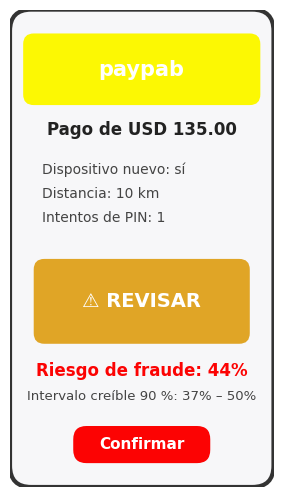

In [ ]:
transaccion = {'dispositivo_nuevo': 1, 'distancia_km': 10, 'ratio': 0.15, 'intentos_pin': 1, 'monto': 135}
probs = prob_fraude(transaccion)                              # ✏️ distribución de probabilidades
print(f'Media {probs.mean():.1%} · intervalo creíble 90 %: {np.percentile(probs, 5):.1%} – {np.percentile(probs, 95):.1%}')
curso.checkpoint(6, probs.mean())
curso.pantalla_app(nombre_app, color_principal, color_alerta, transaccion, probs)

**Simulador interactivo**: mueva los controles. ¿Puede lograr que una transacción con dispositivo nuevo pase como «APROBADA»? ¿Qué pasa con el intervalo cuando lleva las variables a valores extremos?

In [ ]:
curso.simulador(prob_fraude, nombre_app, color_principal, color_alerta)   # interactivo (solo en Colab)

### 💬 Pregunta 3
Para la transacción del Checkpoint 6, ¿qué decisión tomaría y por qué importa el intervalo creíble, no solo la media?

**Respuesta:**

La probabilidad media de fraude es ≈ **43,5 %**, con intervalo creíble del 90 % de ≈ **36,9 % – 49,9 %**. Con el semáforo de la app (< 20 % aprobar, 20–50 % revisar, ≥ 50 % bloquear) la decisión es **REVISAR**: no la aprobaría directamente, sino que pediría una verificación adicional (código por SMS o biometría) antes de liberar el pago.

El intervalo importa porque mide **cuánta confianza tiene el modelo**. Aquí todo el intervalo cae dentro de la franja «revisar», así que la decisión es robusta. Si el intervalo cruzara el 50 %, habría riesgo real de que sea un fraude claro; si fuera muy ancho (por ejemplo con valores extremos de las variables, lejos de los datos de entrenamiento), la media sola daría una falsa sensación de certeza.

---
## Análisis adicional
### A. Explaining away en la red bayesiana
Comparo la probabilidad de desempleo con y sin la evidencia de ingreso bajo.

In [ ]:
p_des_mora = inferencia.query(['Desempleo'], evidence={'Mora': 1}).values[1]
p_des_mora_ib = inferencia.query(['Desempleo'], evidence={'Mora': 1, 'IngresoBajo': 1}).values[1]
print(f'P(Desempleo | Mora)               = {p_des_mora:.3f}')
print(f'P(Desempleo | Mora, IngresoBajo)  = {p_des_mora_ib:.3f}')

P(Desempleo | Mora)               = 0.256
P(Desempleo | Mora, IngresoBajo)  = 0.193


**Interpretación:**

Al observar la mora, la probabilidad de desempleo sube a ≈ 0,256 (frente al 8 % a priori). Pero si además sé que el ingreso es bajo, baja a ≈ 0,193: el ingreso bajo es una **explicación alternativa** de la mora y le «quita» credibilidad al desempleo. Las dos causas son independientes a priori, pero se vuelven **dependientes** al condicionar en su efecto común (estructura en V o *collider*). Esto explica la Pregunta 1.

### B. Incertidumbre de la transacción del Checkpoint 6

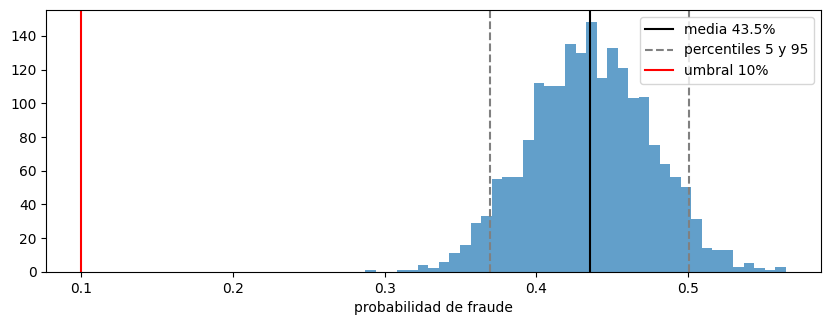

Fracción de muestras sobre el umbral: 100.0%


In [ ]:
umbral = 0.10                                                # umbral de decisión (ajustable)
fig, ax = plt.subplots()
ax.hist(probs, bins=40, alpha=0.7)
ax.axvline(probs.mean(), color='k', label=f'media {probs.mean():.1%}')
ax.axvline(np.percentile(probs, 5), color='gray', ls='--', label='percentiles 5 y 95')
ax.axvline(np.percentile(probs, 95), color='gray', ls='--')
ax.axvline(umbral, color='red', label=f'umbral {umbral:.0%}')
ax.set_xlabel('probabilidad de fraude'); ax.legend(); plt.show()
print(f'Fracción de muestras sobre el umbral: {(probs > umbral).mean():.1%}')

**Interpretación:**

La distribución de la probabilidad de fraude está concentrada entre ≈ 37 % y 50 %, y el **100 %** de las muestras de la posterior supera el umbral del 10 %. No hay duda de que la transacción es riesgosa; la incertidumbre solo afecta a *cuánto*: no alcanza el 50 % para bloquearla, por eso la decisión es «revisar». Un modelo frecuentista daría un solo número; el enfoque bayesiano me permite decir además **con qué seguridad** la transacción supera el umbral.

### C. Sensibilidad al prior
Repito el modelo del Checkpoint 1 con un prior uniforme Beta(1, 1).

In [ ]:
with pm.Model() as modelo_unif:
    tasa_u = pm.Beta('tasa', alpha=1, beta=1)
    pm.Binomial('obs', n=n, p=tasa_u, observed=k)
    tr_unif = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
media_unif = float(tr_unif.posterior['tasa'].mean())
print(f'Prior Beta(2, 20): {media_mcmc:.4f} · prior Beta(1, 1): {media_unif:.4f} · tasa observada: {k / n:.4f}')

Prior Beta(2, 20): 0.0331 · prior Beta(1, 1): 0.0294 · tasa observada: 0.0231


**Interpretación:**

| Prior | Media de la prior | Media posterior |
|---|---|---|
| Beta(2, 20) | 9,1 % | ≈ 3,3 % |
| Beta(1, 1) (uniforme) | 50 % | ≈ 2,9–3,0 % |
| Solo datos (3/130) | — | 2,3 % |

Con 130 transacciones los **datos dominan**: dos priors muy distintos dan posteriores parecidas. Aun así, Beta(2, 20) arrastra la estimación hacia la tasa nacional (≈ 8–9 %), lo cual es razonable porque solo hay 3 fraudes y la tasa observada probablemente subestima el riesgo real. El prior pesa más cuanto menos datos hay; por eso conviene reportar este análisis de sensibilidad.

---
## Análisis adicional II (propuesta propia)
Hasta aquí el modelo se ajustó con `X_train`, pero **`X_test` nunca se usó**. Antes de llevar el modelo a la app hay que responder tres preguntas: ¿predice bien datos que no vio?, ¿qué umbral conviene al negocio? y ¿se puede mejorar el modelo?

### D. Evaluación fuera de muestra con incertidumbre
Calculo la probabilidad de fraude de cada transacción de prueba con las 2000 muestras de la posterior. Así obtengo el **AUC con su propio intervalo creíble**, el **Brier score** (error cuadrático de las probabilidades) y una **curva de calibración**.

AUC test: 0.927 · IC 90 %: 0.924 – 0.929
Brier: 0.0570 (modelo ingenuo 0.0774 → mejora 26%)


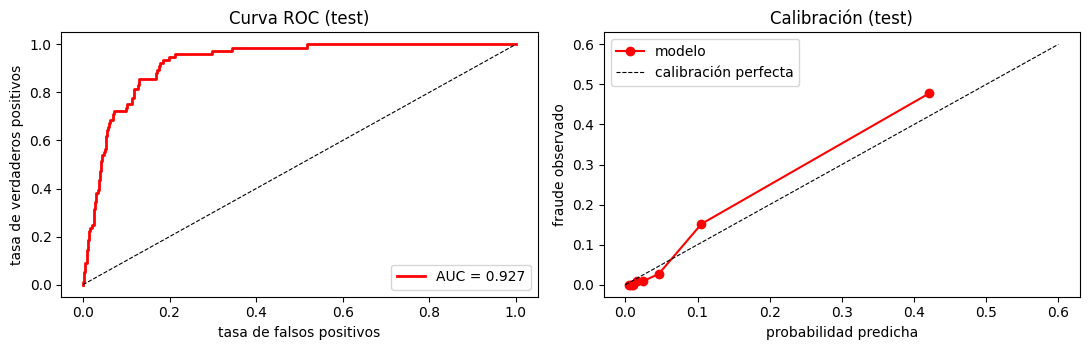

fraude real,0,1,All
decisión de la app,,,
APROBADA,773,25,798
REVISAR,32,33,65
BLOQUEADA,18,18,36
All,823,76,899


In [ ]:
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve

Z_test = ((X_test - media) / desv).values                    # estandarizo con media y desviación de ENTRENAMIENTO
P_test = sigmoide(a_s[:, None] + b_s @ Z_test.T)             # 2000 muestras × n_test transacciones
p_test = P_test.mean(0)                                      # probabilidad media por transacción

auc = roc_auc_score(y_test, p_test)
auc_s = np.array([roc_auc_score(y_test, P_test[s]) for s in range(0, len(a_s), 10)])   # AUC de 200 muestras de la posterior
brier = brier_score_loss(y_test, p_test)
brier_base = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))           # modelo ingenuo: tasa promedio
print(f'AUC test: {auc:.3f} · IC 90 %: {np.percentile(auc_s, 5):.3f} – {np.percentile(auc_s, 95):.3f}')
print(f'Brier: {brier:.4f} (modelo ingenuo {brier_base:.4f} → mejora {1 - brier / brier_base:.0%})')

fpr, tpr, _ = roc_curve(y_test, p_test)
frac_pos, p_pred = calibration_curve(y_test, p_test, n_bins=8, strategy='quantile')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(fpr, tpr, color=color_alerta, lw=2, label=f'AUC = {auc:.3f}'); ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
ax[0].set_xlabel('tasa de falsos positivos'); ax[0].set_ylabel('tasa de verdaderos positivos'); ax[0].set_title('Curva ROC (test)'); ax[0].legend()
ax[1].plot(p_pred, frac_pos, 'o-', color=color_alerta, label='modelo'); ax[1].plot([0, 0.6], [0, 0.6], 'k--', lw=0.8, label='calibración perfecta')
ax[1].set_xlabel('probabilidad predicha'); ax[1].set_ylabel('fraude observado'); ax[1].set_title('Calibración (test)'); ax[1].legend()
plt.tight_layout(); plt.show()

semaforo = pd.cut(p_test, [0, 0.2, 0.5, 1], labels=['APROBADA', 'REVISAR', 'BLOQUEADA'])
pd.crosstab(semaforo, y_test.values, rownames=['decisión de la app'], colnames=['fraude real'], margins=True)

**Interpretación:**

El AUC en test es ≈ **0,93** con un intervalo creíble muy estrecho: el modelo **ordena bien** las transacciones por riesgo en datos nuevos, así que no está sobreajustado. El Brier mejora ≈ 25 % frente al modelo ingenuo, y la curva de calibración sigue de cerca la diagonal: cuando el modelo dice «40 %», ocurre fraude ≈ 40–48 % de las veces.

Pero la tabla del semáforo muestra el punto débil: con el umbral del 20 % la app **aprueba ≈ 25 de los 76 fraudes** (un tercio). Un buen AUC no garantiza una buena decisión: el umbral hay que elegirlo según los costos del negocio.

### E. Umbral óptimo según el costo del negocio
Supuesto: dejar pasar un fraude (falso negativo) cuesta **10 veces** más que molestar a un cliente honesto con una verificación (falso positivo). La teoría bayesiana de decisión dice que conviene revisar cuando p > C_FP / (C_FP + C_FN) = 1/11 ≈ 9 %. Lo compruebo con los datos de prueba.

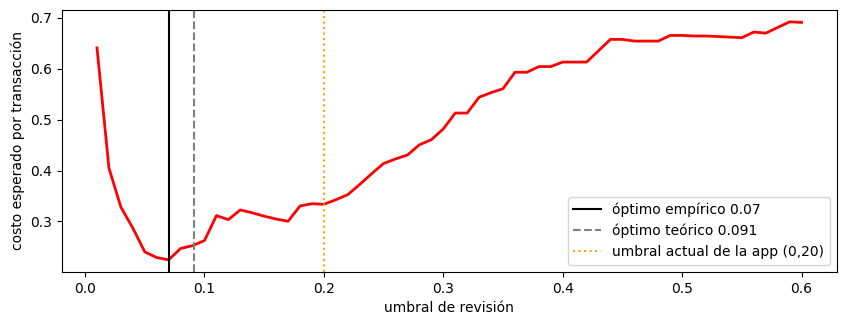

Costo sin modelo (aprobar todo): 0.845 · con umbral 0,20: 0.334 · con umbral óptimo: 0.225


In [ ]:
C_FP, C_FN = 1, 10                                           # costos relativos (supuestos, ajustables)
umbrales = np.linspace(0.01, 0.6, 60)
yt = y_test.values
costo = np.array([(C_FP * ((p_test >= u) & (yt == 0)).sum() + C_FN * ((p_test < u) & (yt == 1)).sum()) / len(yt) for u in umbrales])
u_opt = umbrales[costo.argmin()]
costo_20 = costo[np.abs(umbrales - 0.2).argmin()]

fig, ax = plt.subplots()
ax.plot(umbrales, costo, color=color_alerta, lw=2)
ax.axvline(u_opt, color='k', label=f'óptimo empírico {u_opt:.2f}')
ax.axvline(C_FP / (C_FP + C_FN), color='gray', ls='--', label=f'óptimo teórico {C_FP / (C_FP + C_FN):.3f}')
ax.axvline(0.2, color='orange', ls=':', label='umbral actual de la app (0,20)')
ax.set_xlabel('umbral de revisión'); ax.set_ylabel('costo esperado por transacción'); ax.legend(); plt.show()
print(f'Costo sin modelo (aprobar todo): {C_FN * yt.mean():.3f} · con umbral 0,20: {costo_20:.3f} · con umbral óptimo: {costo.min():.3f}')

**Interpretación:**

El umbral que minimiza el costo (≈ 0,07–0,09) coincide con el valor teórico 1/11, y está muy por debajo del 20 % del semáforo. Con esos costos, a la empresa le conviene **revisar más transacciones**: acepta más falsos positivos baratos a cambio de detener más fraudes caros. Pasar del umbral 0,20 al óptimo baja el costo esperado de ≈ 0,33 a ≈ 0,22 por transacción (≈ 33 % menos), y frente a no usar modelo (≈ 0,85) el ahorro es de casi tres cuartas partes. La recomendación es que el umbral lo fije el negocio a partir de sus costos reales, no por costumbre.

### F. ¿Se puede mejorar el modelo? Interacción dispositivo nuevo × distancia
El modelo es **aditivo**: el efecto de la distancia es el mismo con dispositivo conocido o nuevo. Pero el patrón clásico de fraude es un **dispositivo nuevo lejos de casa** (robo de celular o de credenciales). Pruebo agregar el término de interacción.

In [ ]:
cols2 = cols + ['nuevo_x_dist']
def con_interaccion(X):
    X = X.copy(); X['nuevo_x_dist'] = X['dispositivo_nuevo'] * X['distancia_km']; return X
Xtr2, Xte2 = con_interaccion(X_train), con_interaccion(X_test)
media2, desv2 = Xtr2.mean(), Xtr2.std()
with pm.Model() as modelo_int:
    a2 = pm.Normal('a', mu=0, sigma=2)
    b2 = pm.Normal('b', mu=0, sigma=1, shape=len(cols2))
    pm.Bernoulli('obs', logit_p=a2 + pm.math.dot(((Xtr2 - media2) / desv2).values, b2), observed=y_train.values)
    tr_int = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
diag2 = curso.diagnostico(tr_int, ['b']); diag2.index = cols2
a2_s = tr_int.posterior['a'].values.reshape(-1); b2_s = tr_int.posterior['b'].values.reshape(-1, len(cols2))
p_test2 = sigmoide(a2_s[:, None] + b2_s @ ((Xte2 - media2) / desv2).values.T).mean(0)
comparacion = pd.DataFrame({'AUC test': [auc, roc_auc_score(y_test, p_test2)],
                            'Brier test': [brier, brier_score_loss(y_test, p_test2)]},
                           index=['aditivo (clase)', 'con interacción']).round(4)
display(diag2[['media', 'ic_3%', 'ic_97%', 'r_hat']]); comparacion

,media,ic_3%,ic_97%,r_hat
dispositivo_nuevo,0.2914,0.0631,0.5101,0.9994
distancia_km,0.1135,-0.1165,0.3250,1.0001
ratio,0.8957,0.7490,1.0583,1.0003
intentos_pin,0.6450,0.5055,0.7821,1.0005
nuevo_x_dist,0.9375,0.7009,1.1849,0.9993


,AUC test,Brier test
aditivo (clase),0.9273,0.0570
con interacción,0.9467,0.0496


**Interpretación:**

Con la interacción el modelo mejora en datos nuevos (AUC ≈ 0,927 → **0,947**; Brier ≈ 0,057 → **0,050**) y las cadenas siguen convergiendo (R-hat ≈ 1,00). Lo más interesante está en los coeficientes: el término `nuevo_x_dist` es grande y claramente positivo, mientras que el efecto «solo» de `distancia_km` casi desaparece (su intervalo creíble incluye el 0). Es decir, **estar lejos no es sospechoso por sí mismo; lo sospechoso es estar lejos con un dispositivo nuevo**. El modelo aditivo de la clase mezclaba ambos efectos.

### Conclusiones
1. **MCMC funciona**: PyMC reproduce la posterior exacta beta-binomial (3,31 % vs 3,29 %), lo que da confianza para usarlo en modelos sin fórmula cerrada.
2. **Las redes bayesianas razonan en ambas direcciones** (predictiva y diagnóstica) y capturan efectos poco intuitivos como el *explaining away*.
3. **El modelo jerárquico** corrige la tasa de Imbabura de 2,3 % a ≈ 6,9 %: con pocos datos, tomar prestada información de las demás provincias evita conclusiones exageradas.
4. **La incertidumbre cambia decisiones**: la transacción del Checkpoint 6 debe ir a revisión, y el intervalo confirma que esa decisión es robusta.
5. **Propuesta para la app**: validar fuera de muestra (AUC ≈ 0,93), fijar el umbral según costos (≈ 9 %, no 20 %) e incluir la interacción dispositivo nuevo × distancia (AUC ≈ 0,95).

---
## Deber (20 pts · individual · ≈ 3 horas)
Abra el enlace **«Deber M6»** del aula virtual. Cada estudiante recibe **datos personalizados** según su nombre. Entrega: **Archivo → Guardar (Ctrl+S)** → su repositorio → ruta `deber/deber.ipynb`. **Plazo: domingo 15-nov-2026, 11:00.**

---
## Cierre de la clase

In [ ]:
curso.resumen(total=7)                                      # avance de checkpoints

Estudiante: Cueva Gallo Evelyn Alexandra · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) → su repositorio (hasta las 12:00 del día siguiente sin descuento).


**Para terminar:** revise los ✅ y las 3 preguntas 💬 → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* **el suyo** → ruta `talleres/clase3.ipynb` → mensaje `Clase 3`.